# Batch_03 EDA dossier

Section-by-section analysis of the batch_03 data. Each section states
what is measured and **which design decision it feeds**, and ends with
a Findings block. The **Conclusions** section at the end summarizes all
of them.

Prerequisite read: `00_batch03_overview.ipynb` (sources, schemas,
entity diagram).

## 0. What this data cannot answer

- **No labels** — attribution/conversion data is not in batch_03; no
  CVR, class balance, or label-volume analysis here.
- **No user-level signal** — user/device identifiers are anonymized;
  user features cannot be assessed.
- **No loss side** — the firehose sample is wins-only by construction;
  nothing here describes lost or non-bid auctions.
- **No timing** — every stream timestamp (`rx_timestamp_usecs`,
  `auctionid.timestamp`) was randomized by the anonymization (values
  spread uniformly over 2002–2286). Ordering and delay analysis are
  impossible on the sample; timing comes from the impression-delay
  CSV (section 6).
- **No volume representativity** — 933 events; volumes come from the
  traffic CSVs (section 6), not from the sample.

In [1087]:
import matplotlib.pyplot as plt
import pandas as pd
from itables import init_notebook_mode

from eda_tools import (
    TRAFFIC_DIR,
    load_activity,
    load_candidates,
    load_delivery_control,
    load_firehose,
)

pd.set_option("display.max_columns", 200)
# Databricks-like interactive tables (search/sort/paginate) for every DataFrame
init_notebook_mode(all_interactive=True, connected=False)

events = load_firehose()
candidates = load_candidates()
activity = load_activity()
entities = load_delivery_control()

# Shared derived column (stream timestamps are randomized by the
# anonymization — no datetime derivations are possible on this sample)
candidates["bid_micros"] = pd.to_numeric(candidates["bidding.bid_price_micros"])
print(events.shape, candidates.shape, activity.shape, entities.shape)

(933, 172) (4569, 20) (2660, 20) (130, 84)


## 1. Feature availability at bid time

**Feeds: the candidate feature list and the GBDT input schema**
(request-derived features are the model's main input; this section is
the reason we asked for samples).

- Coverage (non-null %) of every bid-time field: `app.bundle/name/
  publisher`, `device.devicetype/os`, `geo.country` (+ finer geo if
  present), `imp[].video` specs (duration, placement, mimes, skip),
  `imp[].bidfloor`, PMP/deal presence, `cur`, `tmax`,
  `inventory_source`.
- Cardinality + top-k frequencies per categorical; concentration (mass
  in the top 10 bundles / geos).
- Cross-file consistency: field presence per `source_file`,
  `data_center` values, timestamp range per file (regions? days?).

Output: one coverage/cardinality table ranked for feature candidacy.

In [1088]:
# Profile every field available at bid time.
#
# Fields come from two places: the scalar request.bidrequest.* columns, and
# the first imp[] entry (the ad slot and its video specs), flattened as imp0.*.
# Nested fields (lists/dicts such as imp0.video.mimes or imp0.pmp.deals) cannot
# be counted or grouped, so they get coverage (present-or-not) only; scalar
# fields get the full profile.

def is_nested(column: pd.Series) -> bool:
    return column.map(lambda v: isinstance(v, (list, dict))).any()

request_cols = [c for c in events.columns if c.startswith("request.bidrequest.")]
imp0 = pd.json_normalize(events["request.bidrequest.imp"].str[0]).add_prefix("imp0.")

bid_time_fields = pd.concat(
    [events[request_cols + ["request.inventory_source"]].reset_index(drop=True), imp0],
    axis=1,
)

nested_cols = [c for c in bid_time_fields.columns if is_nested(bid_time_fields[c])]
scalars = bid_time_fields.drop(columns=nested_cols)

nested_coverage = (
    bid_time_fields[nested_cols].notna().mean().round(3).rename("coverage").to_frame()
)

inventory = pd.DataFrame({
    "coverage": scalars.notna().mean().round(3),   # share of events carrying a value
    "nunique": scalars.nunique(),                  # distinct values across events
    "top_share": scalars.apply(                    # share held by the most common value
        lambda col: col.value_counts(normalize=True).max()
    ).round(3),
    "top10_share": scalars.apply(                  # share held by the 10 most common values
        lambda col: col.value_counts(normalize=True).head(10).sum()
    ).round(3),
    # every non-null value unique -> anonymized to random tokens; only
    # presence is assessable from this sample, not the distribution
    "anonymized": scalars.nunique() == scalars.notna().sum(),
})

print(f"{len(inventory)} scalar fields profiled; {len(nested_cols)} nested fields (coverage only)")

140 scalar fields profiled; 24 nested fields (coverage only)


In [1089]:
from pprint import pprint

pprint(list(bid_time_fields.columns))

['request.bidrequest.id',
 'request.bidrequest.imp',
 'request.bidrequest.app.id',
 'request.bidrequest.app.name',
 'request.bidrequest.app.bundle',
 'request.bidrequest.app.publisher.id',
 'request.bidrequest.app.publisher.name',
 'request.bidrequest.app.content.livestream',
 'request.bidrequest.app.content.prodq',
 'request.bidrequest.app.storeurl',
 'request.bidrequest.device.ua',
 'request.bidrequest.device.ip',
 'request.bidrequest.device.geo.country',
 'request.bidrequest.device.geo.zip',
 'request.bidrequest.device.make',
 'request.bidrequest.device.os',
 'request.bidrequest.device.devicetype',
 'request.bidrequest.device.lmt',
 'request.bidrequest.device.ifa',
 'request.bidrequest.device.ext.augmented_device_screen_size',
 'request.bidrequest.device.ext.augmented_browser',
 'request.bidrequest.device.ext.augmented_browser_version',
 'request.bidrequest.device.ext.augmented_os',
 'request.bidrequest.device.ext.augmented_osv',
 'request.bidrequest.device.ext.augmented_model',
 'r

`nested_coverage` — list/dict-valued fields (e.g. `imp0.video.mimes`, `imp0.pmp.deals`) cannot be profiled like scalars; **coverage** is the share of events where the field is present at all.

In [1090]:
# Nested bid-time fields (lists/dicts) — how often they are present
nested_coverage

coverage
request.bidrequest.imp                                 1.000
request.bidrequest.device.ext.augmented_models         0.998
request.bidrequest.user.geo.ext.regions                1.000
request.bidrequest.user.data                           0.947
request.bidrequest.user.eids                           0.718
request.bidrequest.user.ext.cross_device_mappin...     0.908
request.bidrequest.user.ext.cross_device_mappin...     0.908
request.bidrequest.user.ext.luids                      0.814
request.bidrequest.user.ext.unified_user_ids           1.000
request.bidrequest.user.ext.bgids                      0.792
request.bidrequest.cur                                 1.000
request.bidrequest.regs.gpp_sid                        0.347
request.bidrequest.source.schain.nodes                 1.000
request.bidrequest.ext.targeting_geo.regions           1.000
request.bidrequest.regs.ext.mspa_applied_sids          0.123
request.bidrequest.app.content.cat                     0.215
request.bidrequest.site.cat                            0.002
request.bidrequest.site.content.cat                    0.002
imp0.video.mimes                                       1.000
imp0.video.protocols                                   1.000
imp0.video.battr                                       1.000
imp0.video.playbackmethod                              1.000
imp0.pmp.deals                                         1.000
imp0.video.api                                         0.075

Columns of `inventory` (one row per scalar bid-time field):

- **coverage** — share of events carrying a value (nulls excluded from everything below).
- **nunique** — distinct values across events.
- **top_share** — share held by the single most common value; ≈1.0 means the field is effectively constant (no signal).
- **top10_share** — share covered by the 10 most common values; high = concentrated, low = spread out.
- **anonymized** — every non-null value is unique (random tokens): only presence is assessable from this sample, not the distribution.

In [1091]:
# Scalar bid-time field inventory — searchable/sortable
inventory.sort_values(["coverage", "nunique"], ascending=[False, False]).reset_index(names="field")

field  coverage  nunique  \
0                                request.bidrequest.id     1.000      933   
1                request.bidrequest.device.geo.country     1.000      933   
2                         request.bidrequest.device.os     1.000      933   
3                 request.bidrequest.device.devicetype     1.000      933   
4    request.bidrequest.device.ext.augmented_device...     1.000      933   
..                                                 ...       ...      ...   
135           request.bidrequest.device.ext.ifv_hashed     0.002        2   
136                    request.bidrequest.user.ext.ifv     0.002        2   
137                 request.bidrequest.site.content.id     0.002        2   
138              request.bidrequest.site.content.title     0.002        2   
139                         request.bidrequest.app.ver     0.002        1   

     top_share  top10_share  anonymized  
0        0.001        0.011        True  
1        0.001        0.011        True  
2        0.001        0.011        True  
3        0.001        0.011        True  
4        0.001        0.011        True  
..         ...          ...         ...  
135      0.500        1.000        True  
136      0.500        1.000        True  
137      0.500        1.000        True  
138      0.500        1.000        True  
139      1.000        1.000       False  

[140 rows x 6 columns]

Columns of `files`:

- **events** — rows (= delivered impressions) in the file.
- **data_centers** — distinct `impression.data_center` values seen; tells whether the files slice by region.

In [1092]:
# Are the three firehose files comparable slices of the same traffic?
#
# Timestamps cannot answer this: the anonymization randomized every stream
# timestamp (values spread uniformly over 2002-2286 instead of clustering in
# October 2026). What remains comparable: event counts and data centers.

def distinct_values(column: pd.Series) -> str:
    return ", ".join(sorted(column.dropna().unique()))

files = events.groupby("source_file").agg(
    events=("auction_key", "size"),
    data_centers=("impression.data_center", distinct_values),
)
files

events          data_centers
source_file                                         
firehose-full-1.ndjson     304  US_EAST_1, US_WEST_2
firehose-full-2.ndjson     319  US_EAST_1, US_WEST_2
firehose-full-3.ndjson     310  US_EAST_1, US_WEST_2

**Findings (1) — feature availability at bid time**

**Shape.** 933 events (304/319/310 per file, one data center each), 4,569
candidates, 2,660 activity events, 130 entities. The bid request exposes
**140 scalar + 24 nested fields**; 65 scalar fields have ≥99% coverage.

**Anonymization cuts deeper than the flag.** 51 full-coverage fields are
all-unique random tokens (`devicetype`, `os`, every geo level below
nothing — `country`, `city`, `zip`, `metro` —, `ua`, `ifa`, `make`,
`us_privacy`, user ids, trackers). Caution: fields with nunique *close
to* the non-null count (`augmented_make` 907/933, `user.geo.zip`
913/920, metros ~580 distinct) are randomized too — token collisions
keep them under the strict all-unique flag. Rule of thumb: **nunique ≈
non-null count ⇒ treat as anonymized.** Net effect: the device, geo,
user, and privacy axes are presence-only in this sample.

**The usable feature core** (high coverage, real variation, not anonymized):

- *App/content identity*: `app.bundle` (61 values, 95%), `app.id` (73,
  97%), `publisher.id/name` (18, 97%), `storeurl`, `app.name`.
- *Content metadata*: `content.genre` (115 values, 82%),
  `contentrating` (26, 84%), `content.len` (71%), `livestream` (97%),
  `network.name` (38%), `channel.name` (27%).
- *Video specs*: `maxduration` (39 values, 15–300 s, median 105),
  `minduration`, `w`/`h`, `mimes`/`protocols`/`playbackmethod` (100%
  as lists), `min/maxbitrate` (~32%).
- *Auction context*: `at` (auction type), `seller_id` (18),
  `inventory_source_rel` (5), `pmp.private_auction`, `pmp.deals`
  (100%), `bidfloor` (41% coverage, USD 5–16, `bidfloorcur` always USD),
  `ext.processing_time_ms`.

**Constants — exclude from any feature list** (~25 fields at
top_share ≥ 0.95): `video.placement`/`plcmt`/`linearity`,
`startdelay`, `lmt`, `test`, `schain.*`, `inventory_source`,
`environment_type`, `player_size`, `content.prodq`,
`content.language` (96% "en"), …

**Inventory is app/CTV, not web**: every `site.*` field is ≤2.6%
coverage — site features are ignorable for the MVP.

**User-side arrays** (`user.data` segments 95%, `eids` 72%,
`luids`/`bgids` ~80%) are present but ids are anonymized **and**
truncated to 3 entries — only presence is observable; their real
signal is unknowable until EDA runs client-side.

**One trap**: `tmax` (150–2,000 ms, median 1,075) is the upstream
exchange's timeout for the DSP, not the ad server's 10 ms budget for
the agent — don't read it as our latency envelope.

**Implication for the feature list**: the sample-evidenced candidates
are app/content identity + content metadata + video specs + auction
context. Device and geo features stay on the list on domain priors
only ("available, signal unverifiable here") — exactly the cut the
EDA-on-real-data phase must close.

## 2. Join & identity dossier

**Feeds: label-join readiness** (the join the whole label build
stands on) and the identity-triplet requirement.

- Key integrity: `auction_key` uniqueness; `requestid_str` uniqueness;
  duplicate events across the three files.
- Standing check: winner-in-candidates (933/933 at ingest).
- Id spaces: DSP integer ids (candidates/impressions) vs `ua_*` UUIDs
  (delivery control); bridge coverage (14 adsets / 121 line items) —
  what share of impression and candidate rows the export can enrich.
- Timestamp sanity: `rx_timestamp_usecs` ranges; impression-before-
  activity ordering violations.

`key_checks` — one row per join-key health check: **result** is what the sample shows, **expected** is what a healthy sample must show, **interpretation** says what passing means for the label build. Any result ≠ expected disqualifies the key as a join key as-is.

In [1093]:
# Can the label build rely on these keys? One row per check:
# "expected" is what a healthy sample shows; any deviation means the key
# cannot serve as a join key as-is.

winners = events[["auction_key", "impression.adgroupid.lineitemid"]].rename(
    columns={"impression.adgroupid.lineitemid": "won_line_item_id"}
)
candidates_with_winner = candidates.merge(winners, on="auction_key")
auctions_won_by_a_listed_candidate = candidates_with_winner.loc[
    candidates_with_winner["line_item_id"] == candidates_with_winner["won_line_item_id"],
    "auction_key",
].nunique()

key_checks = pd.DataFrame([
    {
        "check": "auction_key unique per event",
        "result": f"{events['auction_key'].duplicated().sum()} duplicates",
        "expected": "0 duplicates",
        "interpretation": "one auction = one event; safe key joining events, candidates and activity",
    },
    {
        "check": "requestid_str unique per impression",
        "result": f"{events['impression.requestid_str'].duplicated().sum()} duplicates",
        "expected": "0 duplicates",
        "interpretation": "alternative impression-to-activity join key",
    },
    {
        "check": "won line item listed among the auction's candidates",
        "result": f"{auctions_won_by_a_listed_candidate} of {len(events)} auctions",
        "expected": f"{len(events)} of {len(events)}",
        "interpretation": "candidate arrays are complete: the delivered ad is always one of the listed candidates",
    },
])
key_checks

check               result  \
0                       auction_key unique per event         0 duplicates   
1                requestid_str unique per impression         0 duplicates   
2  won line item listed among the auction's candi...  933 of 933 auctions   

       expected                                     interpretation  
0  0 duplicates  one auction = one event; safe key joining even...  
1  0 duplicates        alternative impression-to-activity join key  
2    933 of 933  candidate arrays are complete: the delivered a...

Columns of `bridge_checks`:

- **stream side** — which stream rows are being matched (impressions or candidates) and on which DSP id.
- **export side** — the delivery-control column holding the same DSP id.
- **rows enrichable** — share of stream *rows* (traffic-weighted, not distinct ids) whose DSP id resolves to an exported entity, i.e. where the stream→config join lands and the row can be enriched with the client-side config (budgets, bid, targeting, hierarchy). Below 100% is expected here: the export is a matched 14-ad-set subset. In production, with the full feed, the same join should approach 100% — a shortfall there would be a data-quality finding.

In [1094]:
# How much of the stream can the delivery-control export enrich?
#
# The export is a matched subset (14 ad sets), not the full catalog, so
# coverage below 100% is expected. The number that matters: the share of
# stream rows whose DSP id resolves to an exported entity — that is the
# share of rows we could enrich with client-side config (budgets, bid,
# targeting) in this sample. In production the delivery-control feed
# covers every ad set, so these shares measure the sample pairing only.
#
# Timestamp-ordering checks are impossible here: stream timestamps are
# randomized by the anonymization (section 0).

adsets = entities[entities["entity_type"] == "adset"]
ad_accounts = entities[entities["entity_type"] == "ad_account"]

def bridge_coverage(stream_ids: pd.Series, export_ids: pd.Series) -> str:
    exported = set(export_ids.dropna().astype(str))
    return f"{stream_ids.astype(str).isin(exported).mean():.0%}"

bridge_checks = pd.DataFrame([
    {
        "stream side": "impressions (won line item)",
        "export side": "adset.beeswax_line_item_id",
        "rows enrichable": bridge_coverage(
            events["impression.adgroupid.lineitemid"], adsets["beeswax_line_item_id"]
        ),
    },
    {
        "stream side": "candidates (line_item_id)",
        "export side": "adset.beeswax_line_item_id",
        "rows enrichable": bridge_coverage(
            candidates["line_item_id"], adsets["beeswax_line_item_id"]
        ),
    },
    {
        "stream side": "impressions (advertiser_id)",
        "export side": "ad_account.beeswax_advertiser_id",
        "rows enrichable": bridge_coverage(
            events["impression.advertiser_id"], ad_accounts["beeswax_advertiser_id"]
        ),
    },
])
bridge_checks

stream side                       export side  \
0  impressions (won line item)        adset.beeswax_line_item_id   
1    candidates (line_item_id)        adset.beeswax_line_item_id   
2  impressions (advertiser_id)  ad_account.beeswax_advertiser_id   

  rows enrichable  
0             45%  
1             28%  
2             62%

**Findings (2) — join & identity**

**Keys are clean at event grain.** `auction_key` and `requestid_str`
are duplicate-free across all 933 events and all three files — either
serves as the event-level join key. The frames reconnect losslessly:
100% of activity events land on an event via `auction_key`, and the
won line item appears among the auction's candidates in **933/933**
events (candidate arrays are complete; the winner is always one of
them).

**Referential integrity survived anonymization; meaning didn't.** The
anonymizer randomized identifier *values* (and all timestamps) but
kept them consistent within an event — joins work, ordering and
cross-event semantics don't. Practical rule: join freely, never
compare or sort identifier/timestamp values across events.

**The label-join pattern is demonstrated in-sample.** The design's
decision-log join `(request_id, candidate_id)` has its exact analog
here — (`auction_key`, `line_item_id`) — and it resolves exactly one
winner per event. What the sample cannot show is the other half of
the label join (impression → attributed conversion): no attribution
data in batch_03.

**Two id spaces, bridged as designed.** The stream carries DSP integer
ids (digit strings); the delivery-control export carries the client's
`ua_*` UUIDs plus the `beeswax_*` bridge columns. The bridge works
mechanically in both directions tested. Coverage in this sample is
pairing-limited, not broken: the 14 exported ad sets are 12% of the
121 distinct line items seen but cover **45% of impression rows** and
28% of candidate rows (the export was matched to high-volume ad
sets); the advertiser bridge reaches **62%** of impressions. In
production the full feed should put these joins near 100% — a
shortfall there becomes a data-quality alarm, not an expectation.

**Not verifiable here**: event ordering/latency (timestamps
randomized, section 0) and any cross-event identity linking (user ids
anonymized). Both wait for client-side data.

## 3. Candidate structure within a request

One request carries several candidates and the model scores all of
them. A feature can only change the **ranking inside a request** if
its value differs between that request's candidates. Fields identical
across a request's candidates (app, device, auction context) still
matter — but as **context**: they move all of the request's
predictions together rather than deciding between candidates.

Measured here: how many candidates a request carries; which candidate
fields actually vary inside a request (ranking signal) vs stay
constant there (context); and whether the winning candidate differs
systematically from the losers.

Distribution of candidates per request, one row per source file:
**count** = number of requests, the rest are distribution stats
(mean/std/min/quartiles/max) of how many candidates each request
carried.

In [1095]:
candidates_per_request = (
    candidates.groupby(["source_file", "auction_key"]).size().rename("candidates")
)
candidates_per_request.groupby("source_file").describe().round(2)

count  mean   std  min  25%  50%  75%   max
source_file                                                        
firehose-full-1.ndjson  304.0  4.92  4.80  1.0  1.0  2.0  8.0  15.0
firehose-full-2.ndjson  319.0  4.96  4.77  1.0  1.0  2.0  8.0  15.0
firehose-full-3.ndjson  310.0  4.80  4.76  1.0  1.0  2.0  8.0  15.0

`field_variation` — one row per column of the candidates frame, **no
exclusions**:

- **varies_within_request** — share of multi-candidate requests where
  the column takes more than one value. 1.0 = always differs between a
  request's candidates (pure ranking signal); 0.0 = constant inside
  every request (context or join key — no ranking power). Columns the
  loader copies from the request (app, device, keys) prove themselves
  as context here by showing 0.0.
- **nunique_overall** — distinct values across all candidate rows, for
  scale. List-valued columns are compared as whole tuples.

In [1096]:
# Ranking signal vs context: does the column differ between the
# candidates of one request? Every column of the frame is profiled;
# constants and request-copied context identify themselves with
# varies_within_request = 0.0.

def comparable(column: pd.Series) -> pd.Series:
    # lists are unhashable; compare them as whole tuples
    return column.map(lambda v: tuple(v) if isinstance(v, list) else v)

multi = candidates.groupby("auction_key").filter(lambda g: len(g) > 1)

field_variation = pd.DataFrame({
    "varies_within_request": {
        column: (
            comparable(multi[column]).groupby(multi["auction_key"]).nunique(dropna=False) > 1
        ).mean().round(3)
        for column in candidates.columns
    },
    "nunique_overall": {
        column: comparable(candidates[column]).nunique() for column in candidates.columns
    },
}).sort_values("varies_within_request", ascending=False)
field_variation

varies_within_request  \
creative_ids                                              1.000   
line_item_id                                              1.000   
campaign_id                                               0.946   
account_id                                                0.925   
bidding.bid_price_micros                                  0.907   
bid_micros                                                0.907   
targeted_segments                                         0.065   
bidding.bid_modifier_multipliers_product                  0.026   
deal_id                                                   0.018   
device.os                                                 0.000   
geo.country                                               0.000   
imp0.bidfloor                                             0.000   
device.devicetype                                         0.000   
source_file                                               0.000   
app.name                                                  0.000   
app.bundle                                                0.000   
buzz_key                                                  0.000   
inventory_source                                          0.000   
pacing.pace_delivery                                      0.000   
auction_key                                               0.000   

                                          nunique_overall  
creative_ids                                          231  
line_item_id                                          140  
campaign_id                                            87  
account_id                                             47  
bidding.bid_price_micros                              162  
bid_micros                                            162  
targeted_segments                                     201  
bidding.bid_modifier_multipliers_product                1  
deal_id                                                19  
device.os                                             933  
geo.country                                           933  
imp0.bidfloor                                          12  
device.devicetype                                     933  
source_file                                             3  
app.name                                               43  
app.bundle                                             61  
buzz_key                                                1  
inventory_source                                        1  
pacing.pace_delivery                                    1  
auction_key                                           933

`bid_by_role` — does the winning candidate carry a higher bid price
than its competitors in the same request?

- **rows**: `winner` = the candidate whose line item was delivered;
  `loser` = the other candidates of the same request.
- **unit**: USD CPM (price per 1,000 impressions). The raw field
  `bidding.bid_price_micros` is micro-USD per impression; CPM
  = micros / 1,000 — e.g. 7,408 micros = USD 7.41 CPM.
- **columns**: distribution stats (count/mean/std/min/quartiles/max).

How to read it: clearly separated distributions mean price dominates
who wins; heavy overlap means other factors decide (the next cell
quantifies that directly).

In [1097]:
scored = candidates.merge(winners, on="auction_key")
scored["role"] = (scored["line_item_id"] == scored["won_line_item_id"]).map(
    {True: "winner", False: "loser"}
)
# micro-USD per impression -> USD CPM, the unit bids are quoted in
scored["bid_cpm_usd"] = scored["bid_micros"] / 1_000
bid_by_role = scored.groupby("role")["bid_cpm_usd"].describe().round(2)
bid_by_role

count  mean   std  min   25%   50%  75%   max
role                                                  
loser   3636.0  6.66  0.80  5.0  6.00  6.41  7.1  13.0
winner   933.0  8.54  3.69  5.0  6.52  7.41  9.0  50.0

`winner_bid_rank` — in multi-candidate requests, where does the
winner's bid sit among its request's candidate bids?

- **winner_bid_rank** — rank of the winning candidate's bid inside its
  request, 1 = highest bid (ties share the better rank).
- **requests** / **share** — how many requests, and their fraction,
  had the winner at that rank.

How to read it: all mass at rank 1 would mean the highest bid always
wins (price decides alone); mass spread over lower ranks means the ad
server's selection weighs more than price (targeting fit, pacing,
frequency capping).

In [1098]:
multi_scored = scored.groupby("auction_key").filter(lambda g: len(g) > 1).copy()
multi_scored["bid_rank"] = (
    multi_scored.groupby("auction_key")["bid_cpm_usd"]
    .rank(method="min", ascending=False)
    .astype(int)
)

winner_bid_rank = (
    multi_scored.loc[multi_scored["role"] == "winner", "bid_rank"]
    .value_counts().sort_index()
    .rename("requests").to_frame()
)
winner_bid_rank["share"] = (
    winner_bid_rank["requests"] / winner_bid_rank["requests"].sum()
).round(3)
winner_bid_rank.index.name = "winner_bid_rank"
winner_bid_rank

requests  share
winner_bid_rank                 
1                     211  0.425
2                      68  0.137
3                      71  0.143
4                      53  0.107
5                      27  0.054
6                      16  0.032
7                      14  0.028
8                      15  0.030
9                      10  0.020
10                      4  0.008
11                      4  0.008
12                      1  0.002
13                      2  0.004

**Findings (3) — candidate structure within a request**

**Load shape is stable.** The three files agree: median 2 candidates
per request, mean ~4.9, max 15, with a bimodal tendency (many
1–2-candidate requests, a cluster around 8+). Serving-cost planning on
"a few candidates typically, ~15 worst case in-sample" holds across
files (the true production max is still pending from the ad-server
vendor).

**What actually varies inside a request — i.e., what the model can
rank on:** candidate identity and price. `creative_ids` and
`line_item_id` differ in 100% of multi-candidate requests (231
distinct creative sets, 140 line items), `campaign_id` in 95%,
`account_id` in 92%, bid price in 91%. Everything the request
contributes (app, content, device, bidfloor) is constant within the
request — confirmed empirically at 0.000. Consequence for the feature
design: **within-request ranking is carried entirely by line-item-side
features** (advertiser, campaign, ad-set and creative attributes) —
consistent with the "advertisers as features" decision; request-side
features act as context that modulates predictions across requests.

**Near-context candidate fields:** `targeted_segments` varies in only
6.5% of requests and `deal_id` in 1.8% (19 deals, 100% presence) —
they sit on the candidate but behave as request-level context here.
`pace_delivery` is constant `true` and the bid modifier is a single
value: no in-sample signal at all.

**Price influences but does not decide.** Winners bid higher (median
USD 7.41 vs USD 6.41 CPM) with a long tail to USD 50 while losers sit tightly
in USD 5–13 — yet the winner holds the **top bid in only 42.5%** of
multi-candidate requests, and winners appear as deep as bid rank 13.
The ad server's selection weighs more than price (targeting fit,
pacing, frequency capping). Two implications: raising our bid buys
probability of delivery, not certainty — and any future win-rate /
bid-landscape model must condition on more than the bid value.

**Caveat:** the sample is wins-only, so "losers" are candidates that
lost to a delivered impression — auctions nobody won are invisible
here, and loser statistics are conditional on that.

## 4. Video activity funnel

After an impression is delivered, the video player sends one message
per playback milestone it crosses: START when the video begins, Q1 at
25% played, MID at 50%, Q3 at 75%, COMPLETE at the end. Each such
message is one row of the activity table — a "playback event". Playback depth is the only post-impression signal in
this sample (attribution is absent), so the question here is whether
"how much of the ad was watched" is worth anything as a model feature
or as an early proxy metric for rollout readouts — the design's
`proxy` evidence mode needs signals that arrive long before
conversions do.

This section answers three questions, one table each:

1. Of the ads that started playing, how many were still playing at
   25%, 50%, 75%, and at the end? (the funnel)
2. How many of these milestone messages does one impression
   typically report?
3. 73 impressions reported no playback events at all — are they
   spread evenly across apps (random loss), or concentrated in a few
   apps (a reporting problem in those apps)?

What we cannot measure: *when* each milestone happened, because the
stream timestamps are randomized (section 0).

`funnel` — one row per playback milestone:

- **impressions** — impressions whose activity includes the milestone.
- **share_of_impressions** — same, as a share of all 933 impressions.
- **share_of_starters** — survival from START; reads as "of the ads
  that began playing, how many got this far."

Caveat: events can be lost in transit — a missing milestone is not
proof playback stopped there.

In [1099]:
MILESTONES = ["START", "Q1", "MID", "Q3", "COMPLETE"]

milestones_reached = activity.groupby("auction_key")["type"].agg(set)

funnel = pd.DataFrame(
    {
        "impressions": [
            int(milestones_reached.map(lambda reached: m in reached).sum())
            for m in MILESTONES
        ]
    },
    index=pd.Index(MILESTONES, name="milestone"),
)
funnel["share_of_impressions"] = (funnel["impressions"] / len(events)).round(3)
funnel["share_of_starters"] = (
    funnel["impressions"] / funnel.loc["START", "impressions"]
).round(3)
funnel

impressions  share_of_impressions  share_of_starters
milestone                                                      
START              848                 0.909              1.000
Q1                 688                 0.737              0.811
MID                528                 0.566              0.623
Q3                 376                 0.403              0.443
COMPLETE           211                 0.226              0.249

`events_per_impression` — how many activity events one impression
reports (0 = the impression is silent): **impressions** holding that
count and their **share** of all 933.

In [1100]:
events_per_impression = (
    events["activity_count"].value_counts().sort_index().rename("impressions").to_frame()
)
events_per_impression.index.name = "activity_events"
events_per_impression["share"] = (
    events_per_impression["impressions"] / len(events)
).round(3)
events_per_impression

impressions  share
activity_events                    
0                         73  0.078
1                        172  0.184
2                        153  0.164
3                        156  0.167
4                        181  0.194
5                        198  0.212

`silent_by_bundle` — do the silent impressions (no activity at all)
cluster in specific apps? One row per app bundle, largest silent
counts first:

- **impressions** / **silent** — the bundle's impressions, and how many
  of them reported no activity.
- **silent_rate** — silent / impressions for the bundle. Compare with
  the overall rate (73 / 933 ≈ 0.078): rates far above it on sizable
  bundles indicate a systematic reporting gap in that app, not noise.

In [1101]:
bundles = events["request.bidrequest.app.bundle"]

silent_by_bundle = pd.DataFrame({
    "impressions": bundles.value_counts(),
    "silent": bundles[events["activity_count"] == 0].value_counts(),
}).fillna(0).astype(int)
silent_by_bundle["silent_rate"] = (
    silent_by_bundle["silent"] / silent_by_bundle["impressions"]
).round(3)
silent_by_bundle.sort_values("silent", ascending=False).head(10)

impressions  silent  silent_rate
request.bidrequest.app.bundle                                  
74519                                  144      18        0.125
151908                                 131       8        0.061
31440                                   72       8        0.111
vizio.streaming                         76       7        0.092
vizio.watchfree                         58       3        0.052
vizio.pluto                             13       3        0.231
G15147002586                            50       3        0.060
vizio.paramountplus                     15       2        0.133
tv.pluto.android                        35       2        0.057
B00KDSGIPK                              49       2        0.041

**Delay from impression to each quartile cannot be measured on this
sample** — stream timestamps are randomized by the anonymization
(section 0). Real delay timing comes from the client's
impression-delay histogram (section 6).

**Findings (4) — video activity funnel**

**Coverage is high, loss is real.** 860 of 933 impressions (92%)
report at least one playback event. But the stream demonstrably drops
events: 12 impressions report quartiles **without a START**, and 24
have non-monotonic sequences (e.g. Q3 present, MID missing). So every
funnel number is a floor, not the truth — "reached Q3" is reliable
evidence, "didn't reach Q3" is not.

**The funnel** (of 848 starters): 81% reach Q1, 62% MID, 44% Q3,
**25% COMPLETE**. For CTV, where ads are typically non-skippable and
completion rates run far higher, 25% is implausibly low as true
abandonment — given the proven event loss, much of the drop-off is
likely *reporting* loss rather than viewers stopping. Treat measured
completion as a lower bound; the true rate needs client-side data.
Besides the five milestones, rare player events exist (PAUSE 7,
RESUME 1, MUTE 1).

**Events per impression are near-uniform** (1–5 events at 172–198
impressions each, plus 73 at zero) — consistent with impressions being
cut off at every depth, loss included, rather than clustering at
"full report" vs "nothing".

**Silent impressions lean toward specific apps.** Overall silent rate
7.8%; bundle `74519` sits at 12.5% (144 impressions), `31440` at
11.1%, `vizio.pluto` at 23% (small base) while others sit near or
below the average — mild but visible per-app concentration,
suggesting per-app reporting differences rather than pure random
loss.

**What this means for us.** Playback depth is post-impression — it
can never be a bid-time input for the impression being scored. Its
two real uses: (1) **aggregated priors** as features (an app's or
line item's historical completion/Q3 rate, computed offline into the
feature tables); (2) **early proxy signal** for rollout readouts —
quartile events arrive during playback, far ahead of any conversion,
which is exactly what the `proxy` evidence mode wants. Both uses need
the event-loss floor understood (and, for pacing of readouts, real
timing — unmeasurable here, section 0).

## 5. Delivery-control config landscape

The delivery-control export is the client's campaign-management
configuration — the same kind of content the future **ad-set settings
feed** will deliver to the bidding agent. The sample is small (12
organizations down to 78 ads), so instead of statistics we look at the
actual rows and answer three questions:

1. What does the configuration look like at each level (statuses,
   budgets, bids, objectives)?
2. Do the two proposed ad-set fields (`bidding_strategy`, `pacing`)
   exist yet — and what does today's raw DSP-side bidding config say?
3. Is the hierarchy referentially intact (every child points to an
   existing parent)?

`status_by_type` — how many entities of each type are ACTIVE vs
PAUSED.

One thing to know when reading it: each entity stores only its **own**
status. Pausing a campaign does not flip its ad sets to PAUSED in this
data — they keep showing ACTIVE. So "ACTIVE" here means "not paused
itself", not "actually eligible to deliver"; to know whether an ad set
would really run, you would have to check its whole parent chain. The
first-stage contract avoids pushing that job into the agent: the
settings feed will carry a single effective status per ad set, already
combining organization, account, and campaign states.

In [1102]:
status_by_type = pd.crosstab(entities["entity_type"], entities["status"])
status_by_type

status        ACTIVE  PAUSED
entity_type                 
ad                53      25
ad_account        12       0
adset             14       0
campaign          13       1
organization      12       0

`campaign_config` — the actual campaign rows, with **every setting the
export fills for campaigns** (rule: all non-null campaign columns;
identifier and bridge columns excluded — those are join keys, covered
in section 2).

Objective of this table: see the configuration reality the agent will
operate in at campaign level. What to look for:

- **objective_type** — how much of today's book is `web_conversions`
  (the CPA world this project serves) vs `awareness` (CPM, no model).
  Here: 3 of 14.
- **budget scale and spread** (`daily_budget`, `lifetime_budget`,
  `budget_type`) — the money range pacing and bidding will manage.
- **flight dates** — open-ended vs fixed-end campaigns.
- **frequency caps** — per-user delivery limits the ad server enforces.
- **uniform vs diverse** — the more diverse these rows, the more
  variety the settings feed and our per-ad-set handling must absorb.

In [1103]:
def config_view(entity_type: str) -> pd.DataFrame:
    """All settings the export fills for one entity type: every column
    with at least one non-null value, minus the type discriminator and
    the identifier/bridge columns (keys, not configuration)."""
    rows = entities[entities["entity_type"] == entity_type].set_index("name")
    rows = rows.dropna(axis=1, how="all")

    # Removing foreign keys that are only noise under that analysis
    keys = [
        c for c in rows.columns
        if c in ("entity_id", "entity_name", "entity_type")
        or c.startswith("ua_") or c.startswith("beeswax_")
    ]
    return rows.drop(columns=keys)

campaign_config = config_view("campaign").sort_values("objective_type")
campaign_config

currency  status  \
name                                                                
Medicare                                              USD  PAUSED   
10/14 - 900GChost - UNI - 2704                        USD  ACTIVE   
10/23 - 900GCsocial - UNI - 5477                      USD  ACTIVE   
10/20 $4k/day SpektraFin FE (EST) (775-306-7758)      USD  ACTIVE   
Medicare Q4 2026                                      USD  ACTIVE   
Golden Plumbing                                       USD  ACTIVE   
10.27.26_M104_TT 90s_Allowance                        USD  ACTIVE   
10.27.26_M233_Emo Music 90s_CSNP                      USD  ACTIVE   
News-Midterms Pulse                                   USD  ACTIVE   
Cannaball Final Expense V2 - Doctor Test              USD  ACTIVE   
ACA-UA                                                USD  ACTIVE   
National - Conversion                                 USD  ACTIVE   
UA Test - Q3'26                                       USD  ACTIVE   
Aura House CTV                                        USD  ACTIVE   

                                                                  budget_type  \
name                                                                            
Medicare                                          spend including vendor fees   
10/14 - 900GChost - UNI - 2704                    spend including vendor fees   
10/23 - 900GCsocial - UNI - 5477                  spend including vendor fees   
10/20 $4k/day SpektraFin FE (EST) (775-306-7758)  spend including vendor fees   
Medicare Q4 2026                                  spend including vendor fees   
Golden Plumbing                                   spend including vendor fees   
10.27.26_M104_TT 90s_Allowance                    spend including vendor fees   
10.27.26_M233_Emo Music 90s_CSNP                  spend including vendor fees   
News-Midterms Pulse                               spend including vendor fees   
Cannaball Final Expense V2 - Doctor Test          spend including vendor fees   
ACA-UA                                            spend including vendor fees   
National - Conversion                             spend including vendor fees   
UA Test - Q3'26                                   spend including vendor fees   
Aura House CTV                                    spend including vendor fees   

                                                  daily_budget  \
name                                                             
Medicare                                              10000.00   
10/14 - 900GChost - UNI - 2704                        30000.00   
10/23 - 900GCsocial - UNI - 5477                      30000.00   
10/20 $4k/day SpektraFin FE (EST) (775-306-7758)       3500.00   
Medicare Q4 2026                                      30000.00   
Golden Plumbing                                          64.14   
10.27.26_M104_TT 90s_Allowance                        50000.00   
10.27.26_M233_Emo Music 90s_CSNP                      50000.00   
News-Midterms Pulse                                        NaN   
Cannaball Final Expense V2 - Doctor Test               3000.00   
ACA-UA                                                 7000.00   
National - Conversion                                  7500.00   
UA Test - Q3'26                                        1500.00   
Aura House CTV                                             NaN   

                                                                 end_at_utc  \
name                                                                          
Medicare                                          2026-12-07T16:00:00-06:00   
10/14 - 900GChost - UNI - 2704                    2026-11-08T22:59:00-06:00   
10/23 - 900GCsocial - UNI - 5477                  2026-11-08T22:59:00-06:00   
10/20 $4k/day SpektraFin FE (EST) (775-306-7758)  2026-11-21T01:59:00-06:00   
Medicare Q4 2026                                  2026-12-31T22:59:00-06:00   
Golden Plumbing                      

### How the ad-set record is organized

The dotted column names are the flattened paths of one nested JSON
object. Its composition:

```mermaid
flowchart LR
  ADSET["ad-set record"]
  ADSET --> KEYS["keys<br/>entity_id = ua_adset_id,<br/>ua_campaign_id, beeswax_*"]
  ADSET --> MONEY["money & flight<br/>bid, bidding.values.cpm_bid,<br/>daily/lifetime_budget, budget_type,<br/>currency, start/end_at_utc"]
  ADSET --> BIDDING["bidding.*<br/>strategy, pacing, pacing_behavior,<br/>catchup_behavior, multiplier,<br/>bid_shading(+control), custom"]
  ADSET --> FCAP["frequency_cap.*<br/>limits[{impressions,duration}],<br/>id_type, id_vendor, use_fallback"]
  ADSET --> TGT1["client-side targeting (readable)<br/>location.{country,region,dma,zipcode},<br/>device_type, genre, segments<br/>— each as .inclusion / .exclusion lists —<br/>day_part, network_app_ids, placement_ids"]
  ADSET --> TGT2["DSP-side targeting (compiled)<br/>targeting.&lt;module&gt;.&lt;mode&gt;.&lt;criterion&gt;.any<br/>lists of {value, comparator}"]
```

**The two targeting blocks say the same thing twice.** The client-side
block is the readable intent (`device_type.inclusion = [desktop, tv,
tablet]`, `location.dma.exclusion = [Alpena MI, …]`). The `targeting.*`
block is the same intent compiled for the DSP, with the naming pattern
`targeting.<module>.<mode>.<criterion>.any`:

- **module** — the dimension family: `geo`, `platform`, `content`,
  `time`, `user`, `app_site`.
- **mode** — how the DSP combines the terms: `any` = at least one must
  match (include-OR), `all` = all must match, `none` = none may match
  (exclusion).
- **criterion** — the attribute: `country`, `region`, `metro` (DMA
  code), `zip`, `device_type` (integer codes), `content_genre`,
  `time_of_week` / `user_time_of_week` (minute-of-week ranges),
  `segment` (boolean expressions over segment ids), `deal_id`.
- each leaf is a list of `{value, comparator}` terms (`equals`,
  `in_range`, `boolean_expression`).

Example: `location.dma.exclusion` (names) and
`targeting.geo.none.metro.any` (DMA codes) are the same exclusion —
once readable, once compiled.

For our lane this block is context, not features: the ad server
evaluates targeting **before** the agent is called, so a candidate's
presence in a request already implies its targeting matched.

Field glossary (the non-obvious ones):

| Field | Meaning |
|---|---|
| `bid` | the advertiser-facing max CPM as configured in the client's Ads Manager, USD |
| `bidding.values.cpm_bid` | the bid actually compiled into the DSP line item — `bid` after the client-side deduction (≤ `bid` on every row; mostly 0.88–0.96 of it, one 0.65 outlier). The future settings feed's `bid` field is specified as this net value |
| `bidding.strategy` | DSP bidding mode; `CPM_PACED` = fixed CPM under pacing (today's only value) |
| `bidding.pacing` / `pacing_behavior` | budget spread unit (`daily`) and curve (`even`) |
| `bidding.catchup_behavior` | how pacing recovers after underdelivery (`even` = spread the deficit) |
| `bidding.bid_shading` + `bid_shading_control` | whether/how the DSP may lower the bid below the configured CPM |
| `bidding.multiplier` | bid modifier product applied on top of the base bid (1.0 = none) |
| `bidding.custom` | whether a custom bidding agent prices this ad set — `False` everywhere today; **our agent flips this world** |
| `budget_type` | what the budget counts; "spend including vendor fees" = gross spend, same basis as the win-log cost |
| `frequency_cap.limits` | list of `{impressions, duration}` caps (can stack, e.g. per-day and per-week) |
| `frequency_cap.id_type` / `id_vendor` | what counts as one "user" for the cap (e.g. HOUSEHOLD by the ad-server vendor) |
| `frequency_cap.use_fallback` | whether to cap on a fallback id when the primary id is missing |
| `day_part.day_parting` | allowed hours per weekday, in the `timezone` referenced (e.g. `ad_account`) |
| `network_app_ids` / `placement_ids` | client-side inventory references the ad set is pinned to |
| `segments.inclusion/.exclusion` | audience segment UUIDs (client-side view; compiled form in `targeting.user`) |

`adset_config` — the actual ad-set rows, same rule as above (every
non-null ad-set setting, keys excluded).

Objective: the ad set is the level the agent bids on — this is the
config that will arrive per record in the settings feed. What to look
for:

- **bid / bidding.values.cpm_bid** — the configured bid, USD CPM.
- **bidding.strategy / .pacing / .pacing_behavior** — today's raw
  DSP-side bidding config; uniformity here (all `CPM_PACED`,
  `daily`/`even`) is the "everything is awareness today" fact in data
  form.
- **bidding.bid_shading** — whether the DSP may shade this ad set's
  bids down.
- **targeting.*, placement/app lists** — the targeting shapes the ad
  server applies before the agent is called.
- **budgets and flight dates** — as on campaigns.

In [1104]:
adset_config = config_view("adset").sort_values("bid", ascending=False)
adset_config

currency  status  \
name                                                    
Nat'l - 15 CPM - Retgt - High Intent      USD  ACTIVE   
News-Midterms Pulse                       USD  ACTIVE   
F25-44 Retail Shopper                     USD  ACTIVE   
11.2.26_M233_Emo Music 90s_CSNP           USD  ACTIVE   
FE $10.09 U65                             USD  ACTIVE   
Premium TV                                USD  ACTIVE   
Shoppers: Female 30+ Peak                 USD  ACTIVE   
CTV_ACA_UA_866-684-3254                   USD  ACTIVE   
11.2.26_M104_TT 90s_Allowance             USD  ACTIVE   
10/14 - 900GChost - UNI - 2704            USD  ACTIVE   
Medicare v2                               USD  ACTIVE   
Universal $7.25                           USD  ACTIVE   
10/23 - 900GCsocial - UNI - 5477          USD  ACTIVE   
6.76 CPM Medicare August 2026             USD  ACTIVE   

                                                      budget_type  \
name                                                                
Nat'l - 15 CPM - Retgt - High Intent  spend including vendor fees   
News-Midterms Pulse                   spend including vendor fees   
F25-44 Retail Shopper                 spend including vendor fees   
11.2.26_M233_Emo Music 90s_CSNP       spend including vendor fees   
FE $10.09 U65                         spend including vendor fees   
Premium TV                            spend including vendor fees   
Shoppers: Female 30+ Peak             spend including vendor fees   
CTV_ACA_UA_866-684-3254               spend including vendor fees   
11.2.26_M104_TT 90s_Allowance         spend including vendor fees   
10/14 - 900GChost - UNI - 2704        spend including vendor fees   
Medicare v2                           spend including vendor fees   
Universal $7.25                       spend including vendor fees   
10/23 - 900GCsocial - UNI - 5477      spend including vendor fees   
6.76 CPM Medicare August 2026         spend including vendor fees   

                                      daily_budget                 end_at_utc  \
name                                                                            
Nat'l - 15 CPM - Retgt - High Intent       2833.33                        NaN   
News-Midterms Pulse                      150000.00  2026-11-03T22:59:00-06:00   
F25-44 Retail Shopper                       700.00                        NaN   
11.2.26_M233_Emo Music 90s_CSNP            7000.00                        NaN   
FE $10.09 U65                              4000.00  2026-12-01T01:59:00-06:00   
Premium TV                                   64.14  2026-11-17T22:59:00-06:00   
Shoppers: Female 30+ Peak                  5000.00                        NaN   
CTV_ACA_UA_866-684-3254                    4000.00                        NaN   
11.2.26_M104_TT 90s_Allowance              5500.00                        NaN   
10/14 - 900GChost - UNI - 2704            20000.00  2026-11-08T22:59:00-06:00   
Medicare v2                                2000.00  2026-12-07T16:00:00-06:00   
Universal $7.25                            1000.00  2026-11-09T22:59:00-06:00   
10/23 - 900GCsocial - UNI - 5477          20000.00  2026-11-08T22:59:00-06:00   
6.76 CPM Medicare August 2026             20000.00  2026-12-31T22:59:00-06:00   

                                      frequency_cap_duration_seconds  \
name                                                                   
Nat'l - 15 CPM - Retgt - High Intent                             NaN   
News-Midterms Pulse                                              NaN   
F25-44 Retail Shopper                                        86400.0   
11.2.26_M233_Emo Music 90s_CSNP                              86400.0   
FE $10.09 U65                                                    NaN   
Premium TV                                                   86400.0   
Shoppers: Female 30+ Peak                                   604800.0   
CTV_ACA_UA_866-684-3254                                      86400.0   
11

`proposed_fields_check` — the batch-02 design proposes two new ad-set
fields; this table shows what the export actually carries, next to
today's raw DSP-side equivalents:

- **non_null** — how many of the 14 ad sets have a value.
- **values** — the distinct values seen.

Reading: the proposed fields are **absent** (all null — the data model
doesn't have them yet), while the raw config exists and is **uniform**:
every ad set runs `CPM_PACED` with `daily`/`even` pacing. Nothing in
production bids by CPA today — exactly what this project adds.

In [1105]:
FIELDS = {
    "bidding_strategy (proposed)": "bidding_strategy",
    "pacing (proposed)": "pacing",
    "bidding.strategy (raw, today)": "bidding.strategy",
    "bidding.pacing (raw, today)": "bidding.pacing",
    "bidding.pacing_behavior (raw, today)": "bidding.pacing_behavior",
}
adsets = entities[entities["entity_type"] == "adset"]

proposed_fields_check = pd.DataFrame(
    {
        label: {
            "non_null": int(adsets[col].notna().sum()),
            "values": ", ".join(sorted(adsets[col].dropna().astype(str).unique())) or "—",
        }
        for label, col in FIELDS.items()
    }
).T
proposed_fields_check

non_null     values
bidding_strategy (proposed)                 0          —
pacing (proposed)                           0          —
bidding.strategy (raw, today)              14  CPM_PACED
bidding.pacing (raw, today)                14      daily
bidding.pacing_behavior (raw, today)       14       even

`hierarchy_check` — referential integrity of the export: for each
child type, does its parent-link UUID point to an exported parent?
**orphans = 0** everywhere means the hierarchy is complete and the
`ua_*_id` links are safe to walk.

In [1106]:
PARENT_LINKS = [
    ("ad_account", "ua_organization_id", "organization"),
    ("campaign", "ua_ad_account_id", "ad_account"),
    ("adset", "ua_campaign_id", "campaign"),
    ("ad", "ua_adset_id", "adset"),
]

def orphan_count(child_type: str, link_col: str, parent_type: str) -> int:
    children = entities[entities["entity_type"] == child_type]
    parents = set(entities.loc[entities["entity_type"] == parent_type, "entity_id"])
    return int((~children[link_col].isin(parents)).sum())

hierarchy_check = pd.DataFrame(
    [
        {
            "child": child,
            "parent link": link,
            "children": int((entities["entity_type"] == child).sum()),
            "orphans": orphan_count(child, link, parent),
        }
        for child, link, parent in PARENT_LINKS
    ]
)
hierarchy_check

child         parent link  children  orphans
0  ad_account  ua_organization_id        12        0
1    campaign    ua_ad_account_id        14        0
2       adset      ua_campaign_id        14        0
3          ad         ua_adset_id        78        0

**Findings (5) — delivery-control config landscape**

**Today's book is pre-CPA, uniformly.** All 14 ad sets run the same raw
DSP bidding config — `CPM_PACED`, `daily`/`even` pacing, `even`
catch-up, multiplier 1.0 — and, decisively, **`bidding.custom = False`
on every ad set**: nothing in production is priced by a custom bidding
agent today. The two proposed fields (`bidding_strategy`, `pacing`) are
absent from the data model (0/14 non-null). Both facts are the
"everything is awareness today; this project adds the CPA world" claim,
verified in data. Campaign objectives agree: 11 `awareness` vs 3
`web_conversions`.

**Config ranges the agent will manage**: bids USD 6.40–14.40 CPM
(matching the stream's bid levels in section 3); daily budgets
USD 64–50,000, lifetime up to 1.5M; bid shading allowed on 12/14 ad
sets; frequency caps per HOUSEHOLD (the ad-server vendor's id), e.g.
1 impression/day; `budget_type` = "spend including vendor fees" — the
same gross basis as the win-log cost, so spend reconciliation needs no
fee adjustment.

**Statuses are per-entity and must not be read as eligibility** — a
child stays ACTIVE under a paused parent (1 paused campaign, 25/78
paused ads here). Per the proposed contract the client resolves the
chain and sends one effective status per ad set; the agent only reads
it.

**Targeting exists twice and is not our filter**: a readable
client-side form (`location.*.inclusion/exclusion`, `device_type.*`,
`segments.*`) and the DSP-compiled `targeting.*` form — same intent.
The ad server enforces it before the agent is called. Its value to the
ML lane is as **candidate-describing features**: targeting breadth
(segment count, geo granularity, device breadth), frequency-cap
tightness, budget scale, bought segments — available on day one of any
new ad set, which makes them a **cold-start feature family** for the
sparse-signal requirement. Serving mechanics already exist: derive
offline in the shared feature layer, write to the feature tables +
Redis, lib looks up by candidate id — no agent enrichment. Deliberate
exclusion pending a decision: `bid`/target-CPA as a feature (couples
the probability to the advertiser's price-setting and feeds back into
our own bid).

**Hierarchy is referentially intact** (0 orphans on all four links) —
the `ua_*_id` chain is safe to walk.

**Caveat**: 14 ad sets, matched to the firehose sample — a
high-volume subset, not evidence of catalog-wide config diversity.

## 6. Traffic & workload metrics (client-measured)

The firehose sample says nothing about volume or timing — 933 events,
randomized timestamps. These five CSVs are the only ground truth for
both, measured by the client over **Oct 1–29, 2026**. They feed two
design inputs: **capacity sizing** (what the agent and the ML slice
must handle) and **freshness budgets** (how stale spend/win information
inherently is).

The section walks through:

1. what the files are (`traffic_files`);
2. the **traffic profile** — daily volumes, the hour-of-day rhythm
   (and why auctions and bids peak at different hours), whole-period
   totals and rates;
3. **impression delay** — the freshness floor of the win log;
4. the **live working set** — line items / campaigns bidding per hour;
5. **per-second rates** — the ingress numbers capacity planning starts
   from.

`traffic_files` — the five client-measured CSVs this section reads,
one row per file: what it measures, its grain, and its size. All cover
October 1–29, 2026 unless noted.

In [1107]:
DESCRIPTIONS = {
    "Traffic profile 20261102.csv":
        "auctions, bids, wins, cost, bid/win rate, CPM — one row per 15-minute interval",
    "Impression delay histogram.csv":
        "bid-to-impression delay — one row per second-bucket, with cumulative %",
    "Active Campaigns and Active Lines per Hour.csv":
        "line items and campaigns receiving at least one bid — one row per hour",
    "Auction Requests per second.csv":
        "auction requests per second — one summary row of percentiles",
    "Bids per second.csv":
        "bid responses per second — one summary row of percentiles",
}

rows = []
for path in sorted(TRAFFIC_DIR.glob("*.csv")):
    csv = pd.read_csv(path)
    rows.append({
        "file": path.name,
        "measures": DESCRIPTIONS.get(path.name, "—"),
        "rows": len(csv),
        "columns": ", ".join(csv.columns),
    })
traffic_files = pd.DataFrame(rows).set_index("file")
traffic_files

measures  \
file                                                                                                
Active Campaigns and Active Lines per Hour.csv  line items and campaigns receiving at least on...   
Auction Requests per second.csv                 auction requests per second — one summary row ...   
Bids per second.csv                             bid responses per second — one summary row of ...   
Impression delay histogram.csv                  bid-to-impression delay — one row per second-b...   
Traffic profile 20261102.csv                    auctions, bids, wins, cost, bid/win rate, CPM ...   

                                                 rows  \
file                                                    
Active Campaigns and Active Lines per Hour.csv    697   
Auction Requests per second.csv                     1   
Bids per second.csv                                 1   
Impression delay histogram.csv                  46963   
Traffic profile 20261102.csv                     2768   

                                                                                          columns  
file                                                                                               
Active Campaigns and Active Lines per Hour.csv  bid_hour, unique_lines_with_bids, unique_campa...  
Auction Requests per second.csv                 avg_rps, p25_rps, p50_rps, p75_rps, p90_rps, p...  
Bids per second.csv                             avg_bps, p25_bps, p50_bps, p75_bps, p90_bps, p...  
Impression delay histogram.csv                  impress_delay_seconds_bucket, impressions, cum...  
Traffic profile 20261102.csv                    bid_interval, estimated auctions, bids, impres...

**Traffic profile** — the base table for the three cells below.
One row per 15-minute interval, Oct 1–29. Columns:

- **bid_interval** — the interval's start timestamp.
- **estimated auctions** — auction requests in the interval; *estimated*
  because the auction log is sampled and the query scales counts ×100.
- **bids** — bid responses returned (eligible + passed pacing + priced).
- **impressions_won** — bids that won and delivered.
- **estimated_cost** — USD paid for those wins in the interval.
- **bid_rate_pct** — bids / auctions ×100, per interval.
- **win_rate_pct** — wins / bids ×100, per interval.
- **winning_cpm** — USD paid per 1,000 won impressions, per interval.

In [1108]:
traffic_profile = pd.read_csv(
    TRAFFIC_DIR / "Traffic profile 20261102.csv", parse_dates=["bid_interval"]
)
display(traffic_profile)

bid_interval  estimated auctions      bids  impressions_won  \
0    2026-10-01 00:00:00           256821200    234593            73533   
1    2026-10-01 00:15:00           263834300    242702            82923   
2    2026-10-01 00:30:00           248214700    246136            80511   
3    2026-10-01 00:45:00           244655600    229220            80054   
4    2026-10-01 01:00:00           243635800    223662            80166   
...                  ...                 ...       ...              ...   
2763 2026-10-29 18:45:00           430734000  88897066           349071   
2764 2026-10-29 19:00:00           469776200  81442091           304150   
2765 2026-10-29 19:15:00           471086800  79012009           314217   
2766 2026-10-29 19:30:00           490807300  84937360           312720   
2767 2026-10-29 19:45:00           407402100  62307449           304138   

      estimated_cost  bid_rate_pct  win_rate_pct  winning_cpm  
0             685.23          0.09         31.34         9.32  
1             775.65          0.09         34.17         9.35  
2             743.35          0.10         32.71         9.23  
3             743.69          0.09         34.92         9.29  
4             737.23          0.09         35.84         9.20  
...              ...           ...           ...          ...  
2763         2976.30         20.64          0.39         8.53  
2764         2582.58         17.34          0.37         8.49  
2765         2666.34         16.77          0.40         8.49  
2766         2653.55         17.31          0.37         8.49  
2767         2554.68         15.29          0.49         8.40  

[2768 rows x 8 columns]

**Daily volumes.** One line per metric, one point per day: how many
auctions reached the bidder, how many bids it returned, how many
impressions it won. What to look for: day-to-day stability vs trend,
weekday/weekend rhythm, and the sheer scale gap between the three
(auctions are ~20× bids, bids ~100× wins).

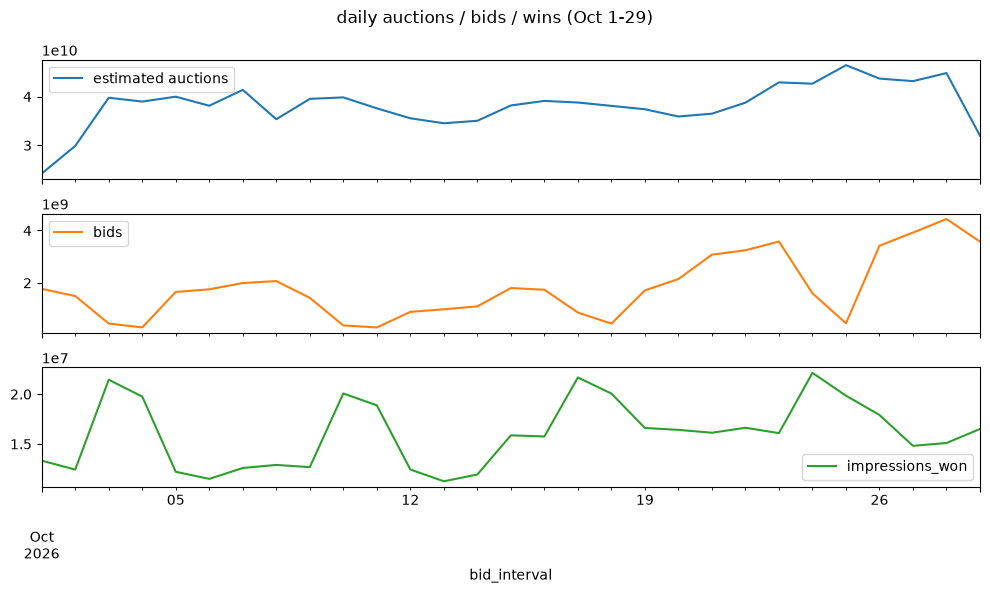

In [1109]:
daily = (
    traffic_profile.set_index("bid_interval")
    .resample("D")[["estimated auctions", "bids", "impressions_won"]]
    .sum()
)
daily.plot(subplots=True, figsize=(10, 6), title="daily auctions / bids / wins (Oct 1-29)")
plt.tight_layout()
plt.show()

**Hour-of-day profile.** Mean volume per 15-minute interval, grouped
by hour (UTC as delivered). What to look for: the peak-to-trough swing
— the peak sizes serving capacity, the trough is when batch windows
hurt least; and whether bids follow the auction curve or have their
own shape (pacing effects).

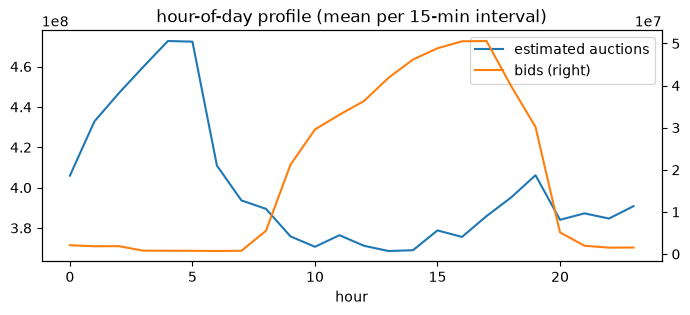

In [1110]:
hourly = (
    traffic_profile.assign(hour=traffic_profile["bid_interval"].dt.hour)
    .groupby("hour")[["estimated auctions", "bids"]]
    .mean()
)
hourly.plot(
    secondary_y="bids", figsize=(8, 3),
    title="hour-of-day profile (mean per 15-min interval)",
)
plt.show()

**Why the two peaks don't line up: auctions follow viewers, bids follow
money.** The auction peak at 0–5 UTC is US prime time (20:00–00:00 ET)
— peak CTV viewing. The bid peak at 15–20 UTC is 10:00–15:00 ET — the
middle of the **budget day**, which resets at US-local midnight (≈04–05
UTC), right after prime time ends. Through the US morning budgets are
fresh and the ad server's probabilistic pacing lets lines participate;
by prime time — the last hours of the budget day — daily budgets are
largely spent and pacing throttles participation exactly when auctions
peak. Corroboration in this same batch: per-interval `bid_rate_pct`
swings 0.09%–34% (pacing opening/closing the tap), and sample ad sets
carry business-hours dayparting (e.g. 14:00–19:00) concentrating bids
mid-day.

Consequence: the bid curve's shape is a **pacing artifact, not
demand**. Size capacity against the auction curve (that is what reaches
the agent); expect the bid curve to change once the client's λ-pacing
takes over from the ad server's α.

`whole_period` — the Oct 1–29 aggregates, computed over totals (not
averages of per-interval rates):

- **bid_rate** — bids / auctions: how often the bidder answered at all.
- **win_rate** — wins / bids: how often an answer won.
- **winning_cpm_usd** — total cost / wins × 1,000: the average paid
  price per thousand impressions.

In [1111]:
def human_count(n: float) -> str:
    """1_234_567_890 -> '1.23 B' — readable magnitudes."""
    for divisor, unit in [(1e12, "T"), (1e9, "B"), (1e6, "M"), (1e3, "K")]:
        if abs(n) >= divisor:
            return f"{n / divisor:.2f} {unit}"
    return f"{n:.0f}"

auctions = traffic_profile["estimated auctions"].sum()
bids = traffic_profile["bids"].sum()
wins = traffic_profile["impressions_won"].sum()
cost = traffic_profile["estimated_cost"].sum()

whole_period = pd.DataFrame(
    [
        {"metric": "auctions", "value": human_count(auctions), "exact": f"{int(auctions):,}"},
        {"metric": "bids", "value": human_count(bids), "exact": f"{int(bids):,}"},
        {"metric": "impressions_won", "value": human_count(wins), "exact": f"{int(wins):,}"},
        {"metric": "spend", "value": f"USD {human_count(cost)}", "exact": f"USD {cost:,.0f}"},
        {"metric": "bid_rate", "value": f"{bids / auctions:.2%}", "exact": ""},
        {"metric": "win_rate", "value": f"{wins / bids:.2%}", "exact": ""},
        {"metric": "winning_cpm", "value": f"USD {1000 * cost / wins:.2f}", "exact": ""},
    ]
).set_index("metric")
whole_period

value              exact
metric                                        
auctions             1.11 T  1,107,953,647,200
bids                52.59 B     52,588,563,746
impressions_won    464.93 M        464,932,980
spend            USD 4.63 M      USD 4,626,743
bid_rate              4.75%                   
win_rate              0.88%                   
winning_cpm        USD 9.95

**Impression delay** — the gap between the bid and the impression
event arriving in the win log, from the client's per-second histogram.
This delay floors how fresh spend/win data can ever be (pacing inputs,
rollout guardrails, label-side joins).

`delay_percentiles` — the real percentiles computed from the histogram
(**seconds** and **minutes** per percentile). Note: the client's prose
said "90% within 15 minutes"; the histogram puts 15 minutes at ~81%
and p90 at ~24 minutes — the table below is the authority.

In [1112]:
delay = pd.read_csv(TRAFFIC_DIR / "Impression delay histogram.csv")

def delay_at(cumulative_pct: float) -> float:
    reached = delay["cumulative_pct"] >= cumulative_pct
    return float(delay.loc[reached, "impress_delay_seconds_bucket"].iloc[0])

delay_percentiles = pd.DataFrame(
    [
        {"percentile": f"p{pct}", "seconds": delay_at(pct), "minutes": round(delay_at(pct) / 60, 1)}
        for pct in (50, 80, 90, 95, 99)
    ]
).set_index("percentile")
delay_percentiles

seconds  minutes
percentile                  
p50           140.0      2.3
p80           847.0     14.1
p90          1451.0     24.2
p95          2293.0     38.2
p99          4689.0     78.2

The same distribution as a curve: cumulative % of impressions (y)
arrived within x seconds of the bid (x, log scale; dotted lines = the
percentiles above). What to look for: the long tail — half the
impressions arrive within ~2 minutes, but closing the last 10% takes
beyond 24 minutes.

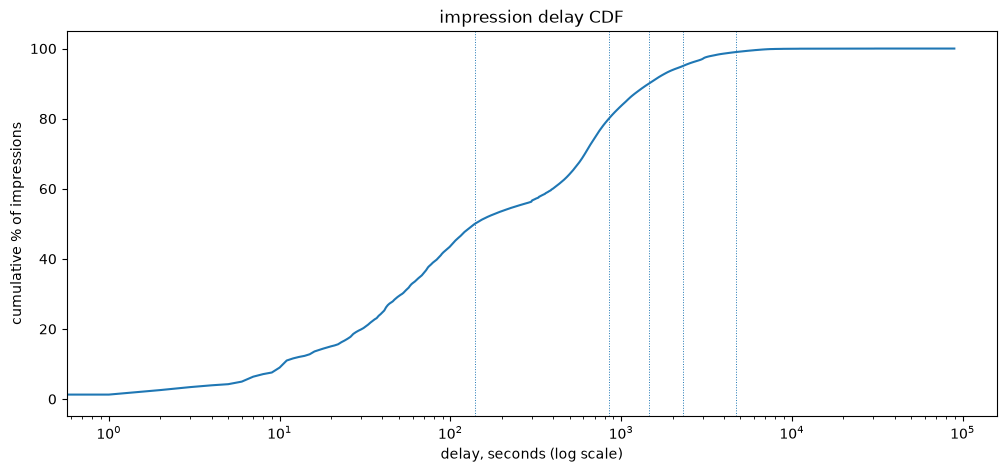

In [1113]:
ax = delay.plot(
    x="impress_delay_seconds_bucket", y="cumulative_pct",
    logx=True, legend=False, figsize=(12, 5), title="impression delay CDF",
)
ax.set_xlabel("delay, seconds (log scale)")
ax.set_ylabel("cumulative % of impressions")
for seconds in delay_percentiles["seconds"]:
    ax.axvline(seconds, ls=":", lw=0.7)
plt.show()

**How many line items and campaigns are actually bidding, hour by
hour.** Each point counts the distinct line items (blue) and campaigns
(orange) that returned **at least one bid** in that hour — a measure of
the live working set, not of how many exist or are enabled (a paused or
fully-throttled line simply doesn't appear).

What to look for:

- the typical level — on average ~630 line items and ~344 campaigns are
  bidding in any given hour;
- the daily cycle and any dips or jumps — sudden drops would mean
  pacing shutting lines down en masse or a delivery incident.

Why it matters to us: this is the number of concurrently live line
items — it sizes the per-line state the agent and pacing hold, the
hot-feature keyspace (features are keyed per line item / ad set), and
the scale of the settings feed the agent consumes.

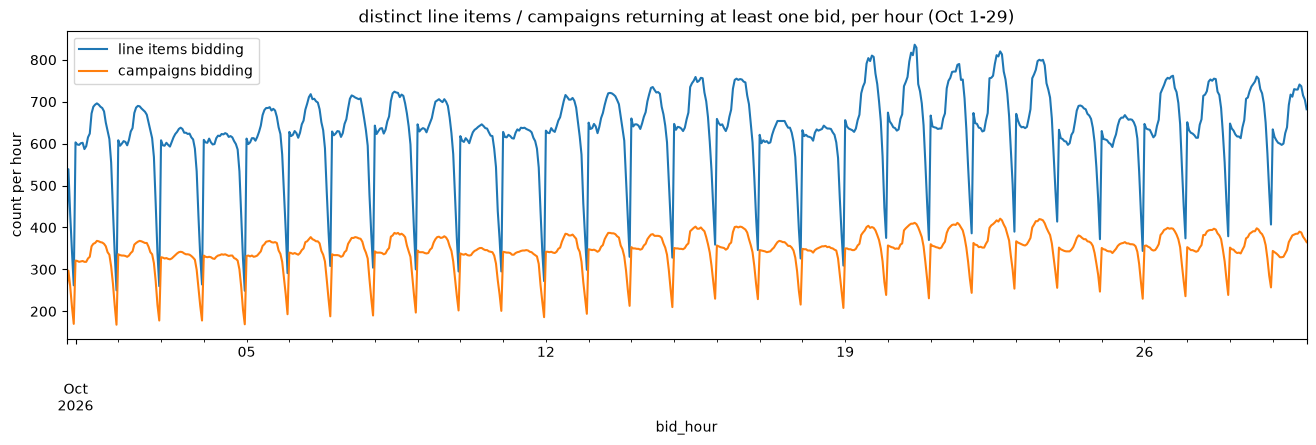

In [1114]:
active_per_hour = pd.read_csv(
    TRAFFIC_DIR / "Active Campaigns and Active Lines per Hour.csv",
    parse_dates=["bid_hour"],
).set_index("bid_hour")

active_per_hour = active_per_hour.rename(columns={
    "unique_lines_with_bids": "line items bidding",
    "unique_campaigns_with_bids": "campaigns bidding",
})

active_per_hour[["line items bidding", "campaigns bidding"]].plot(
    figsize=(16, 4),
    title="distinct line items / campaigns returning at least one bid, per hour (Oct 1-29)",
    ylabel="count per hour",
)
plt.show()

`per_second_rates` — the client's per-second summary over Oct 1–29:
**auctions_per_s** (rows of the auction log per second; sampled log
scaled ×100) vs **bids_per_s** (bid responses per second). Rows are the
distribution stats the client computed (avg, p25…p99, max). The avg/p99
auction figures size normal/worst-case ingress; the bid figures are
~20× smaller and far spikier (pacing).

In [1115]:
auctions_per_s = pd.read_csv(TRAFFIC_DIR / "Auction Requests per second.csv")
bids_per_s = pd.read_csv(TRAFFIC_DIR / "Bids per second.csv")

per_second_rates = pd.DataFrame({
    "auctions_per_s": auctions_per_s.iloc[0].values,
    "bids_per_s": bids_per_s.iloc[0].values,
}, index=["avg", "p25", "p50", "p75", "p90", "p99", "max"])
per_second_rates.map(human_count)

auctions_per_s bids_per_s
avg       443.87 K    20.98 K
p25       387.24 K        811
p50       439.91 K     4.33 K
p75       496.62 K    29.92 K
p90       564.29 K    66.24 K
p99       692.97 K   141.94 K
max         1.92 M   373.00 K

**Findings (6) — traffic & workload**

**Scale.** Oct 1–29: **1.11 T auctions → 52.6 B bids (4.75%) → 465 M
wins (0.88%) → USD 4.63 M spend**, average winning CPM USD 9.95.
Ingress: avg ~444 K auctions/s, p99 ~693 K, **max 1.92 M/s**. Bids are
~20× fewer and far spikier (p25 811/s vs max 373 K/s) — pacing opens
and closes the tap.

**Auctions follow viewers; bids follow money.** Auctions peak at 0–5
UTC (US prime time); bids peak at 15–20 UTC (mid **budget day**, which
resets at US-local midnight ≈ 04–05 UTC). By prime time — the last
hours of the budget day — budgets are largely spent and the ad
server's probabilistic pacing throttles participation exactly when
auctions peak. The bid curve is a **pacing artifact, not demand**:
capacity must be sized on the auction curve, and the bid curve will
reshape when the client's λ-pacing replaces the ad server's α.

**Back-of-envelope ML load** (combining with section 3 and the
client's candidates-per-auction averages): at ~444 K auctions/s
average, scoring ≈ 1.3 candidates/auction (ad-server pacing retained)
means ~0.6 M candidate scores/s fleet-wide; with pacing elimination
removed (13.9 avg) it is ~6 M/s — a 10× swing that dominates the
serving-fleet budget. The worst case still depends on the
vendor-pending per-request maximum.

**Freshness floor.** Impression delay from the histogram (the
authority — the client prose's "90% in 15 min" is actually 81%):
**p50 2.3 min, p80 14 min, p90 24 min, p95 38 min, p99 78 min**.
Consequence: spend/win-based signals (pacing inputs, rollout
guardrails, early readouts) are complete only ~1–1.5 h after the fact;
anything faster acts on partial data by design. Irrelevant for daily
label builds.

**The live working set is small.** ~630 line items / ~344 campaigns
bidding per hour, stable with a daily cycle. Per-line state, the
hot-feature keyspace (keyed per line item), and the settings feed are
all in the hundreds-to-low-thousands range — trivial scale; the hard
numbers live in requests/s, not in entity counts.

## 7. Economics of the won impressions

What did these impressions cost, and how do the auction's prices relate
to each other? Three questions, one per block:

1. **What was bid and what was charged** (`prices_cpm`) — the price
   levels of the business today, and how the charged amount relates to
   the submitted bid (fees), plus how much bid shading cuts
   (`shading_reduction`).
2. **How the winner's price compares to its competitors'**
   (`bid_landscape`) — what winning actually required in auctions that
   had competing candidates.
3. A **sanity check**: do the sample's prices agree with the traffic
   profile's whole-period CPM of ~USD 10 (section 6)?

Why this matters to our lane: when the agent starts bidding
`CPA × P(action)`, an overestimated probability turns directly into an
overpriced bid — knowing today's price levels anchors the **max-bid
cap** discussion (the contract asks who caps CPA bids). And any future
**win-rate model** (`P(win | bid, context)` — the research direction
for evaluating models without a live test) would be fit exactly on
these price-vs-outcome relationships.

`prices_cpm` — one row per won impression, holding that impression's
money fields. The stream stores prices in micro-USD per impression; we
show them as **USD CPM** (price per 1,000 impressions = micros / 1,000).

Background needed to read the columns: before sending a bid to the
exchange, the DSP may apply **bid shading** — lowering the price it is
willing to pay, to avoid overpaying in the auction. So an impression
has three prices in its life:

1. the **original bid** — not a column here; it can be reconstructed as
   the sent bid plus the shading cut (shown two cells below);
2. **bid_cpm_usd** — the price actually **sent to the exchange**, after
   shading. `exchange_bid_cpm_usd` is a duplicate of it — identical on
   all 933 rows;
3. **win_cpm_usd** — the money **charged** for the impression after it
   won.

**win_over_bid** = `win_cpm_usd / bid_cpm_usd`. If winning cost exactly
what was sent, this is 1.0. In the data it is usually **above** 1.0
(two of three impressions; median 8% above, about USD 0.60 CPM): the
charge is bigger than the bid. The most likely explanation: the win
log records the **all-in charge** — media price plus the vendor's fees
— which is exactly how the win-log contract describes its cost field
("media plus targeting and other fees"). To be confirmed with the
client.

In [1116]:
STREAM_PRICE_FIELDS = {
    "bid_cpm_usd": "impression.bid_price_micros_usd",
    "win_cpm_usd": "impression.win_price_micros_usd",
    "exchange_bid_cpm_usd": "impression.exchange_bid_price_micros_usd",
}

prices_cpm = pd.DataFrame(
    index=pd.Index(events["auction_key"].values, name="auction_key")
)
for cpm_name, raw_field in STREAM_PRICE_FIELDS.items():
    prices_cpm[cpm_name] = pd.to_numeric(events[raw_field], errors="coerce").values / 1_000

prices_cpm["win_over_bid"] = prices_cpm["win_cpm_usd"] / prices_cpm["bid_cpm_usd"]
prices_cpm.describe().round(2)

bid_cpm_usd  win_cpm_usd  exchange_bid_cpm_usd  win_over_bid
count       933.00       933.00                933.00        933.00
mean          8.54         8.98                  8.54          1.06
std           3.69         3.63                  3.69          0.07
min           5.00         5.42                  5.00          0.40
25%           6.52         7.15                  6.52          1.00
50%           7.41         8.10                  7.41          1.08
75%           9.00         9.59                  9.00          1.10
max          50.00        50.00                 50.00          1.30

Distribution of **win_over_bid**: the spike at 1.0 is impressions
charged exactly the submitted bid; the mass just above 1.0 is the fee
overhead (typically up to ~1.2); values below 1.0 are rare (14
impressions). This is **not** the shading saving — shading already
happened before `bid_cpm_usd`, and is quantified next.

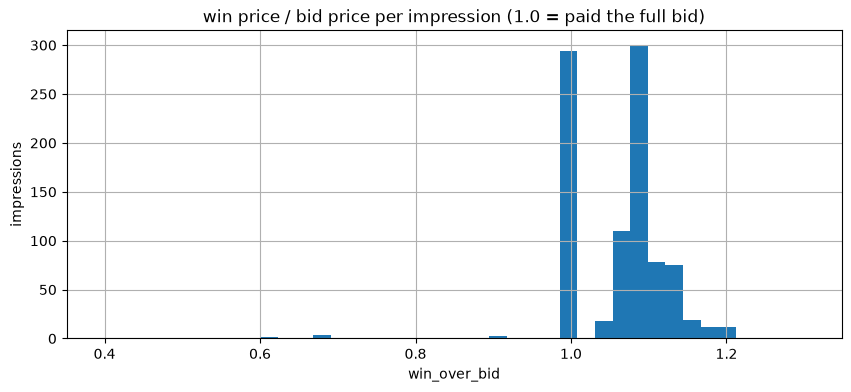

In [1117]:
prices_cpm["win_over_bid"].hist(bins=40, figsize=(10, 4))
plt.title("win price / bid price per impression (1.0 = paid the full bid)")
plt.xlabel("win_over_bid")
plt.ylabel("impressions")
plt.show()

`shading_reduction` — the stream's per-impression shading report
(`bid_shade_reduction_micros`, as USD CPM): how much the DSP cut from
the pre-shading bid to produce the submitted `bid_cpm_usd`. Present on
706 of 933 impressions (653 with a cut > 0); absent elsewhere (no
shading applied or not reported).

In [1118]:
shading_reduction_cpm = (
    pd.to_numeric(
        events["impression.bid_shading_info.bid_shade_reduction_micros"], errors="coerce"
    )
    / 1_000
)
shading_reduction_cpm.describe().round(2).rename("reduction_cpm_usd").to_frame()

reduction_cpm_usd
count             706.00
mean                1.50
std                 1.35
min                 0.00
25%                 0.90
50%                 1.60
75%                 1.85
max                18.21

`bid_landscape` — comparing the charged price with the **best losing
candidate's bid**, all in USD CPM. 496 of the 933 requests have losing
candidates; the other 437 carried only one candidate (the winner), so
there are no losers to compare against.

- **win_cpm_usd** — what the won impression was charged.
- **max_loser_bid_cpm_usd** — the highest bid among that auction's
  losing candidates.
- **win_vs_max_loser** — the ratio. A median near 1.0 means winners
  end up paying right at the level of their best competitor — what a
  shaded first-price auction converges to.

In [1119]:
losing_best_bid_cpm = (
    scored[scored["role"] == "loser"]
    .groupby("auction_key")["bid_cpm_usd"].max()
    .rename("max_loser_bid_cpm_usd")
)
bid_landscape = prices_cpm.join(losing_best_bid_cpm, how="inner")
bid_landscape["win_vs_max_loser"] = (
    bid_landscape["win_cpm_usd"] / bid_landscape["max_loser_bid_cpm_usd"]
)
print(f"auctions with at least one losing candidate: {len(bid_landscape)}")
bid_landscape[["win_cpm_usd", "max_loser_bid_cpm_usd", "win_vs_max_loser"]].describe(
    percentiles=[0.5, 0.9]
).round(2)

auctions with at least one losing candidate: 496


win_cpm_usd  max_loser_bid_cpm_usd  win_vs_max_loser
count       496.00                 496.00            496.00
mean          8.06                   7.67              1.07
std           3.27                   0.94              0.48
min           5.42                   5.00              0.58
50%           7.48                   7.46              1.01
90%           9.27                   8.67              1.21
max          50.00                  13.00              6.75

**Findings (7) — economics of the won impressions**

**Price levels are single-digit CPMs.** Submitted bids: median USD 7.41
CPM (mean 8.54); charged: median USD 8.10 (mean 8.98), max 50. This
agrees with the traffic profile's whole-period CPM of USD 9.95
(section 6) — the sample's economics are not exotic.

**The charge runs above the bid — the win log looks all-in.** Charged
exceeds the submitted bid on 625 of 933 impressions (median +USD 0.60
CPM, ≈ 8%), is equal on 294, lower on just 14. That matches the
win-log contract's cost definition ("media plus targeting and other
fees") and the ad sets' `budget_type` = "spend including vendor fees"
(section 5): one coherent gross-cost basis across config, win log, and
budgets — so spend reconciliation needs no fee adjustment. Still to
confirm with the client. Side note: `exchange_bid_price` duplicates
`bid_price` on every row — carries no extra information.

**Bid shading is material.** The DSP reports a shading cut on 706 of
933 impressions (653 with a cut > 0), median **USD 1.60 CPM** — about
18% of the median bid. The permission flag is on for 12 of 14 sample
ad sets (section 5). Any price the agent returns may be shaded
downstream the same way: the bid we compute is not the price that
competes.

**Winners pay their competitor's price.** In the 496 requests with
losing candidates, the charged price sits at the best losing bid
(median ratio 1.01, p90 1.21) — the shaded first-price market clears
near the second-highest bid. Combined with section 3 (top bid wins
only 42.5% of the time), price-vs-outcome here is rich enough to be
the training ground for the win-rate / bid-landscape research
direction — but a useful model needs the loss side too, which this
wins-only sample cannot provide.

**Max-bid-cap anchor.** Today's market lives at USD 5–15 CPM. A CPA
bid of `target_CPA × P(action)` with an overestimated probability can
exceed that by orders of magnitude (USD 25 target × P=1 → USD 25,000
CPM). These numbers are the concrete case for the cap the contract
asks about — and a plausible default scale for it.

**Caveats**: wins-only (no prices from lost auctions), 14 ad sets'
worth of demand, 933 events.

## Conclusions

What this batch tells us, in short:

**Features (1).** The bid request gives us a solid feature core:
app/content identity, content metadata (genre, rating, length), video
specs, and auction context. Device, geo, and user fields exist but are
anonymized in the sample — we know they arrive at bid time, not whether
they help. The inventory is app/CTV; web fields are empty. About 25
fields are constants and go straight to the exclude list.

**Joins (2).** All keys are clean and every table connects: candidates
and activity join their event, the winner is always among the
candidates, and the DSP-id bridge to the client's config works. The
label join's other half — attribution — is not in this batch, so no
label work is possible yet.

**What the model ranks (3).** Inside one request, only the candidates'
identity (line item, creatives, campaign, advertiser) and bid differ;
everything about the request itself is shared context. This confirms
the "advertisers as features" design. The highest bid wins only ~42%
of the time — the ad server picks winners on more than price.

**Playback signal (4).** 92% of impressions report video milestones,
but events get lost in transit, so completion numbers are floors, not
truth. Useful later as historical aggregates per app/line item and as
an early health signal during rollouts — never as a bid-time input.

**Client config (5).** Nothing bids by CPA today: every ad set runs
paced CPM and no custom bidding agent exists (`bidding.custom` is false
everywhere) — this project is the change. The config itself (targeting
breadth, caps, budgets) is a good source of day-one features for new
ad sets. The entity hierarchy is intact.

**Traffic (6).** Big and uneven: ~444 K auctions/s on average, 1.92 M/s
peak. Bids follow budgets, not viewers — the bid curve is shaped by
pacing, so capacity must be sized on the auction curve. Depending on
the ad server's pacing, ML scoring load swings 10× (~0.6 M to ~6 M
candidate scores/s). Win-log data is only complete ~1–1.5 h after the
fact — that is the freshness floor for spend-based signals.

**Economics (7).** The market lives at USD 5–15 CPM. Charges include
vendor fees (same gross basis as budgets — consistent). Bid shading
cuts a median 18% off the bid, and winners end up paying their best
competitor's price. A CPA-driven bid with an overestimated probability
can blow past these levels by orders of magnitude — a strong, concrete
case for the max-bid cap.

**The sample's hard limits**, to keep in mind everywhere: wins only, no
attribution data, anonymized ids and timestamps, 933 events from 14 ad
sets.

**What flows onward from here:** two client follow-ups (confirm the
budget consumption basis — always the charged price including fees, or
do other consumption types exist; and a sample of attribution data, if
possible), the feature list for the model design, the capacity numbers
for serving, and the max-bid-cap case for the contract discussion.
In-sample timing is not a follow-up: order-preserving timestamps are
only possible inside the client's infrastructure (data protection), so
timing analysis waits for access.